# Perceptron
## AND, OR, and NAND (Single Neuron)

In [10]:
### A single neuron can easily learn 
### AND, OR, and NAND because these gates are linearly 
### separable—meaning you can draw a single straight line to 
### separate the true outputs from the false outputs.

### Pure Numpy Implementation

In [11]:
## Import library
import numpy as np 
import math 

In [12]:
## Activation function


def sigmoid(Z):
    value = 1 / (1 + np.exp(-Z))
    return value


## sigmoid derivative(sig)
def sigmoid_derivative(sig):
    return sig * (1-sig)

In [13]:
## Dataset Truth Table
X = np.array([[0, 0], [0, 1], [1, 0], [1,1]])

y_and = np.array([[0], [0], [0], [1]]) 
y_or = np.array([[0], [1], [1], [1]]) 
y_nand = np.array([[1], [1], [1], [0]])

In [15]:
def train_single_neuron(X, y, epochs = 10000, lr = 0.5):
    ## Initializing Weights and Biass Randomly
    np.random.seed(42)
    weights = np.random.randn(2, 1)
    bias = np.random.randn(1)

    for epoch in range(epochs):
        z = np.dot(X, weights) + bias
        prediction = sigmoid(z)

        error = prediction - y

        # 3. Gradients (Backpropagation for single layer)
        # d_weights = X_transpose dot (error * derivative_of_sigmoid)
        d_weights = np.dot(X.T, error * sigmoid_derivative(prediction))
        d_bias = np.sum(error * sigmoid_derivative(prediction))

        ## Update the Weights and Bias

        weights -= lr * d_weights
        bias -= lr * d_bias

    return weights, bias, prediction

## Train AND
print("*" * 10)
w, b, preds = train_single_neuron(X, y_and)
print("AND Gate Predictions:")
print(np.round(preds)) 

## Train OR
print("*" * 10)
w, b, preds = train_single_neuron(X, y_or)
print("OR Gate Predictions:")
print(np.round(preds)) 

## Train NAND
print("*" * 10)
w, b, preds = train_single_neuron(X, y_nand)
print("NAND Gate Predictions:")
print(np.round(preds)) 

**********
AND Gate Predictions:
[[0.]
 [0.]
 [0.]
 [1.]]
**********
OR Gate Predictions:
[[0.]
 [1.]
 [1.]
 [1.]]
**********
NAND Gate Predictions:
[[1.]
 [1.]
 [1.]
 [0.]]


In [ ]:
## XOR == Gives wrong
## Try drawing a single straight line on that graph that separates
##  the zeros from the ones. It is impossible. You need two lines (or a curved boundary)
##  to separate them. This is why a single-layer perceptron fails on XOR.

y_xor = np.array([[0], [1], [1], [0]])

print("*" * 10)
w, b, preds = train_single_neuron(X, y_xor)
print("XOR Gate Predictions:")
print(np.round(preds)) 

**********
XOR Gate Predictions:
[[0.]
 [0.]
 [0.]
 [0.]]


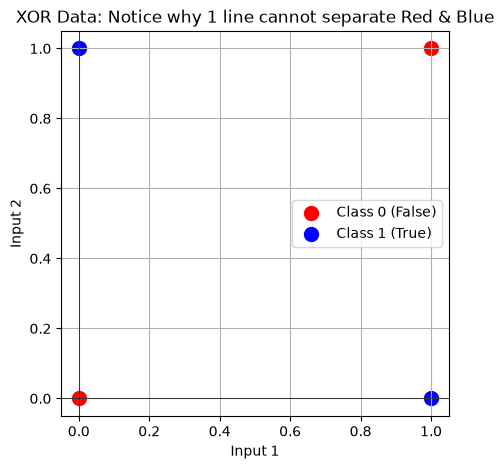

In [17]:
import matplotlib.pyplot as plt

# XOR Dataset
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

# Plotting
plt.figure(figsize=(5, 5))
plt.scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1], color='red', label='Class 0 (False)', s=100)
plt.scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], color='blue', label='Class 1 (True)', s=100)
plt.title("XOR Data: Notice why 1 line cannot separate Red & Blue")
plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.grid(True)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend()
plt.show()